# Fetal Health Classification - Model Training

**Workflow (run top to bottom - *Restart & Run All* works):**

1. Setup and data checks
2. Compare baseline models with **cross-validation on the training set only**
3. Tune the best model (GridSearchCV, training set only)
4. Evaluate on the **test set once**, with per-class metrics and an uncertainty interval
5. Feature-selection experiment (like-for-like comparison)
6. Save models, metadata and results

> The test set has only 35 and 58 samples in the two minority classes, so single-split
> test scores are noisy. Cross-validation on the training set is used for every *decision*;
> the test set is used only for the final report.

## 1. Setup and data checks

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    GridSearchCV,
    RepeatedStratifiedKFold,
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

sys.path.append(str(Path("..").resolve()))
from src.evaluation import (
    bootstrap_macro_f1_ci,
    per_class_table,
    plot_confusion_matrix,
    summarize,
)

SEED = 42
TARGET = "Fetal_Health"
DATA_DIR = Path("../data/processed")
RESULTS_DIR = Path("../results")
FIG_DIR = RESULTS_DIR / "figures"
MODEL_DIR = Path("../models")
for d in (RESULTS_DIR, FIG_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 140)
print("Setup complete.")

Setup complete.


In [2]:
train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

X_train, y_train = train_df.drop(columns=TARGET), train_df[TARGET]
X_test, y_test = test_df.drop(columns=TARGET), test_df[TARGET]

print("Train:", X_train.shape, "| Test:", X_test.shape)

# Sanity checks
print("Missing values  :", int(train_df.isna().sum().sum() + test_df.isna().sum().sum()))
print("Duplicate rows  :", int(train_df.duplicated().sum()), "(train),", int(test_df.duplicated().sum()), "(test)")
overlap = test_df.merge(train_df.drop_duplicates(), on=list(train_df.columns), how="inner")
print("Train/test overlap:", len(overlap), "rows")

dist = pd.DataFrame({
    "train": y_train.value_counts().sort_index(),
    "train %": (y_train.value_counts(normalize=True).sort_index() * 100).round(1),
    "test": y_test.value_counts().sort_index(),
    "test %": (y_test.value_counts(normalize=True).sort_index() * 100).round(1),
})
dist.index.name = "class"
dist

Train: (1690, 21) | Test: (423, 21)
Missing values  : 0
Duplicate rows  : 0 (train), 0 (test)
Train/test overlap: 0 rows


,train,train %,test,test %
class,,,,
0,1316,77.9,330,78.0
1,140,8.3,35,8.3
2,234,13.8,58,13.7


**Class labels.** The classes are the integers 0, 1, 2. Their clinical meaning is not stored in the
data files; see the README ("Class labels") - plots and tables here use the raw ids on purpose.
Class 0 is the large majority (~78%), so **Macro F1** (every class weighted equally) is used for
model selection instead of accuracy.

## 2. Compare baseline models (cross-validation on the training set)

In [3]:
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=5000, random_state=SEED)
    ),
    "Decision Tree": DecisionTreeClassifier(random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=100, random_state=SEED, eval_metric="mlogloss"),
}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

rows = []
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
    rows.append({"Model": name, "CV Macro F1 (mean)": scores.mean(), "CV Macro F1 (std)": scores.std()})

cv_results = pd.DataFrame(rows).sort_values("CV Macro F1 (mean)", ascending=False).reset_index(drop=True)
cv_results.to_csv(RESULTS_DIR / "cv_model_comparison.csv", index=False)
display(cv_results.round(4))

best_model_name = cv_results.loc[0, "Model"]
print("Best baseline model (by CV Macro F1):", best_model_name)

,Model,CV Macro F1 (mean),CV Macro F1 (std)
0,XGBoost,0.8969,0.0241
1,Random Forest,0.8808,0.0256
2,Decision Tree,0.8547,0.0124
3,Logistic Regression,0.7802,0.0235


Best baseline model (by CV Macro F1): XGBoost


## 3. Hyperparameter tuning (GridSearchCV, training set only)

In [4]:
param_grids = {
    "Logistic Regression": {
        "logisticregression__C": [0.01, 0.1, 1, 10, 100],
        "logisticregression__class_weight": [None, "balanced"],
    },
    "Decision Tree": {
        "max_depth": [None, 5, 10, 15, 20],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4],
    },
    "Random Forest": {
        "n_estimators": [100, 200],
        "max_depth": [None, 10, 20],
        "min_samples_split": [2, 5],
        "min_samples_leaf": [1, 2],
    },
    "XGBoost": {
        "n_estimators": [100, 200],
        "max_depth": [3, 5, 7],
        "learning_rate": [0.05, 0.1],
        "min_child_weight": [1, 3],
    },
}

grid_search = GridSearchCV(
    estimator=clone(models[best_model_name]),
    param_grid=param_grids[best_model_name],
    cv=5,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1,
)
grid_search.fit(X_train, y_train)

best_tuned_model = grid_search.best_estimator_
print("Best parameters:", grid_search.best_params_)
print("Best CV Macro F1 (5-fold):", round(grid_search.best_score_, 4))

Fitting 5 folds for each of 24 candidates, totalling 120 fits


Best parameters: {'learning_rate': 0.1, 'max_depth': 3, 'min_child_weight': 1, 'n_estimators': 200}
Best CV Macro F1 (5-fold): 0.9005


## 4. Final evaluation on the test set (used once)

All baselines and the tuned model are fitted on the full training set and scored on the test set.

In [5]:
final_models = {name: clone(m) for name, m in models.items()}
final_models[f"{best_model_name} (tuned)"] = best_tuned_model

test_rows, test_preds = [], {}
for name, model in final_models.items():
    if name not in {f"{best_model_name} (tuned)"}:
        model.fit(X_train, y_train)
    pred = model.predict(X_test)
    test_preds[name] = pred
    test_rows.append({"Model": name, **summarize(y_test, pred)})

model_results = pd.DataFrame(test_rows)
model_results = model_results.merge(
    cv_results[["Model", "CV Macro F1 (mean)"]], on="Model", how="left"
)
model_results.loc[
    model_results["Model"] == f"{best_model_name} (tuned)", "CV Macro F1 (mean)"
] = grid_search.best_score_
model_results.to_csv(RESULTS_DIR / "model_results.csv", index=False)
display(model_results.round(4))
print("Note: the tuned row's CV score is the 5-fold grid-search score; the others use 5x3 repeated CV.")

,Model,Accuracy,Precision,Recall,F1-score,Macro F1,CV Macro F1 (mean)
0,Logistic Regression,0.9362,0.9389,0.9362,0.9371,0.8745,0.7802
1,Decision Tree,0.9078,0.9057,0.9078,0.9064,0.8389,0.8547
2,Random Forest,0.9669,0.9673,0.9669,0.9655,0.9383,0.8808
3,XGBoost,0.9645,0.9640,0.9645,0.9635,0.9358,0.8969
4,XGBoost (tuned),0.9716,0.9716,0.9716,0.9709,0.9511,0.9005


Note: the tuned row's CV score is the 5-fold grid-search score; the others use 5x3 repeated CV.


In [6]:
tuned_name = f"{best_model_name} (tuned)"
tuned_pred = test_preds[tuned_name]

print("Per-class results on the test set -", tuned_name)
display(per_class_table(y_test, tuned_pred).round(3))

ci_lo, ci_hi = bootstrap_macro_f1_ci(y_test, tuned_pred, seed=SEED)
tuned_scores = summarize(y_test, tuned_pred)
print(f"Test Macro F1 = {tuned_scores['Macro F1']:.4f}  (95% bootstrap CI: {ci_lo:.4f} - {ci_hi:.4f})")

tuning_results = pd.DataFrame([{
    "Model": best_model_name,
    "Baseline_CV_Macro_F1": cv_results.loc[0, "CV Macro F1 (mean)"],
    "Tuned_CV_Macro_F1": grid_search.best_score_,
    "Tuned_Test_Macro_F1": tuned_scores["Macro F1"],
    "Test_Macro_F1_CI_low": ci_lo,
    "Test_Macro_F1_CI_high": ci_hi,
    "Tuned_Accuracy": tuned_scores["Accuracy"],
    "Tuned_Precision": tuned_scores["Precision"],
    "Tuned_Recall": tuned_scores["Recall"],
    "Tuned_F1": tuned_scores["F1-score"],
    "Best_Parameters": str(grid_search.best_params_),
}])
tuning_results.to_csv(RESULTS_DIR / "tuning_results.csv", index=False)
display(tuning_results.round(4))

Per-class results on the test set - XGBoost (tuned)


,Class,Precision,Recall,F1-score,Support
0,0,0.971,0.997,0.984,330
1,1,1.000,0.943,0.971,35
2,2,0.961,0.845,0.899,58


Test Macro F1 = 0.9511  (95% bootstrap CI: 0.9205 - 0.9765)


,Model,Baseline_CV_Macro_F1,Tuned_CV_Macro_F1,Tuned_Test_Macro_F1,Test_Macro_F1_CI_low,Test_Macro_F1_CI_high,Tuned_Accuracy,Tuned_Precision,Tuned_Recall,Tuned_F1,Best_Parameters
0,XGBoost,0.8969,0.9005,0.9511,0.9205,0.9765,0.9716,0.9716,0.9716,0.9709,"{'learning_rate': 0.1, 'max_depth': 3, 'min_ch..."


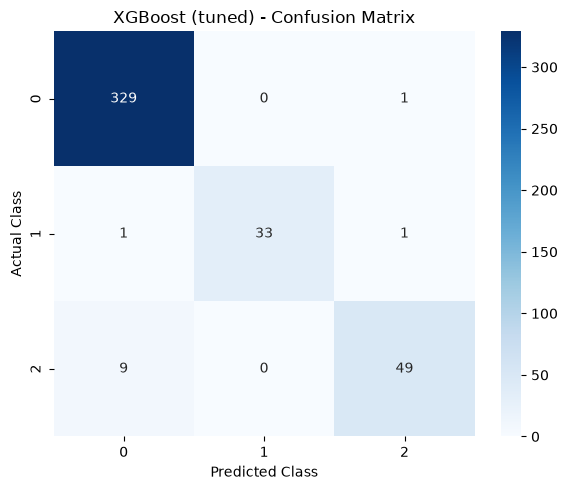

Confusion matrices saved to results/figures/


In [7]:
slug = lambda s: s.lower().replace(" (tuned)", "_tuned").replace(" ", "_")

for name, pred in test_preds.items():
    fig = plot_confusion_matrix(
        y_test, pred, f"{name} - Confusion Matrix",
        save_path=FIG_DIR / f"{slug(name)}_confusion_matrix.png",
    )
    if name == tuned_name:
        plt.show()
    plt.close(fig)
print("Confusion matrices saved to results/figures/")

## 5. Feature-selection experiment

Impurity-based Random Forest importance (fitted on the **training set only**) ranks the 21 CTG
features, and the top 10 are kept. Two checks keep this honest:

* **Permutation importance** on a held-out slice of the training data is shown next to the
  impurity ranking, because impurity importance splits credit between correlated features
  (`Mean`, `Mode` and `Median` are correlated at roughly 0.9-0.95).
* The 21-feature and 10-feature models are compared with the **same settings**, using
  cross-validation as the main evidence.

In [8]:
selector = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
selector.fit(X_train, y_train)

feature_importance = (
    pd.DataFrame({"Feature": X_train.columns, "Importance": selector.feature_importances_})
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

TOP_N = 10
selected_features = feature_importance.head(TOP_N)["Feature"].tolist()
print("Selected features (impurity importance):", selected_features)

# Cross-check with permutation importance on an internal validation split of the TRAIN data
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=SEED
)
rf_check = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1).fit(X_fit, y_fit)
perm = permutation_importance(
    rf_check, X_val, y_val, scoring="f1_macro", n_repeats=20, random_state=SEED, n_jobs=-1
)
perm_df = (
    pd.DataFrame({"Feature": X_train.columns, "Permutation importance": perm.importances_mean})
    .sort_values("Permutation importance", ascending=False)
    .reset_index(drop=True)
)
perm_top = perm_df.head(TOP_N)["Feature"].tolist()
shared = [f for f in selected_features if f in perm_top]
print(f"Top-{TOP_N} by permutation importance:", perm_top)
print(f"Overlap between the two top-{TOP_N} lists: {len(shared)}/{TOP_N}")
print("Only in impurity list:", [f for f in selected_features if f not in perm_top])
print("Only in permutation list:", [f for f in perm_top if f not in selected_features])

(DATA_DIR / "selected_features.txt").write_text("\n".join(selected_features) + "\n", encoding="utf-8")

Selected features (impurity importance): ['ASTV', 'MSTV', 'ALTV', 'Mean', 'Mode', 'Median', 'DP', 'AC', 'MLTV', 'LB']


Top-10 by permutation importance: ['ASTV', 'MSTV', 'ALTV', 'UC', 'AC', 'Mean', 'FM', 'Width', 'MLTV', 'Nmax']
Overlap between the two top-10 lists: 6/10
Only in impurity list: ['Mode', 'Median', 'DP', 'LB']
Only in permutation list: ['UC', 'FM', 'Width', 'Nmax']


46

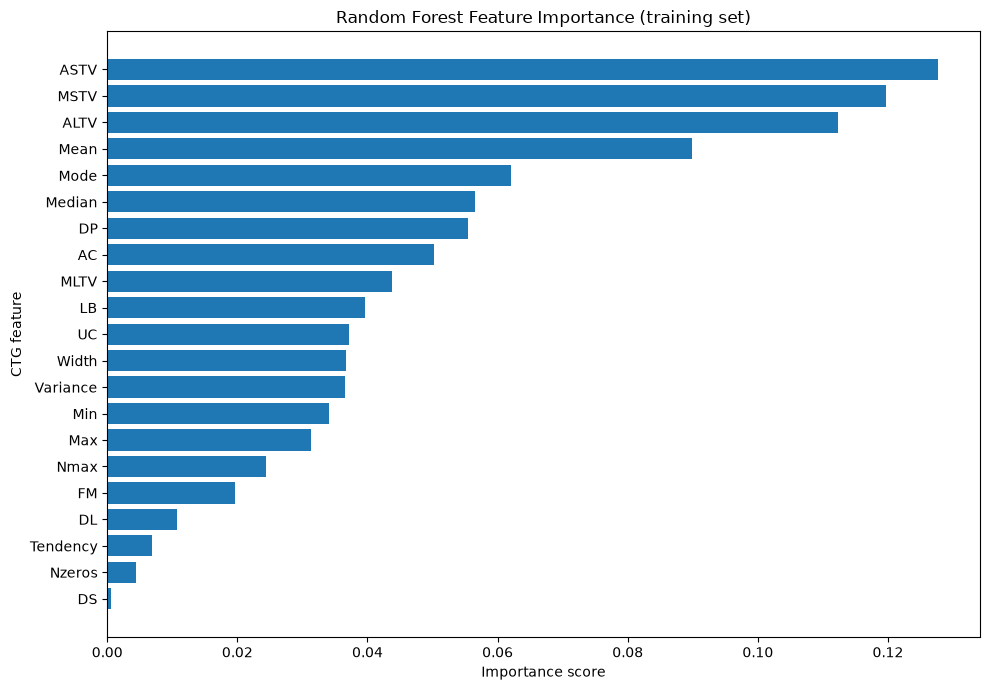

In [9]:
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(feature_importance["Feature"][::-1], feature_importance["Importance"][::-1])
ax.set_title("Random Forest Feature Importance (training set)")
ax.set_xlabel("Importance score")
ax.set_ylabel("CTG feature")
fig.tight_layout()
fig.savefig(FIG_DIR / "random_forest_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
# Like-for-like comparison: same model, same settings, 21 vs 10 features
candidates = {
    "Random Forest (200 trees)": RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
    f"{best_model_name} (tuned params)": clone(best_tuned_model),
}
feature_sets = {"All 21 features": list(X_train.columns), f"Top {TOP_N} features": selected_features}

rows, fitted_reduced = [], {}
for model_name, base in candidates.items():
    for fs_name, cols in feature_sets.items():
        cv_scores = cross_val_score(clone(base), X_train[cols], y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
        est = clone(base).fit(X_train[cols], y_train)
        pred = est.predict(X_test[cols])
        fitted_reduced[(model_name, fs_name)] = est
        s = summarize(y_test, pred)
        rows.append({
            "Model": model_name,
            "Feature set": fs_name,
            "Number of Features": len(cols),
            "CV Macro F1 (mean)": cv_scores.mean(),
            "CV Macro F1 (std)": cv_scores.std(),
            "Test Accuracy": s["Accuracy"],
            "Test Precision": s["Precision"],
            "Test Recall": s["Recall"],
            "Test F1-score": s["F1-score"],
            "Test Macro F1": s["Macro F1"],
        })

fs_comparison = pd.DataFrame(rows)
fs_comparison.to_csv(RESULTS_DIR / "feature_selection_comparison.csv", index=False)
display(fs_comparison.round(4))

,Model,Feature set,Number of Features,CV Macro F1 (mean),CV Macro F1 (std),Test Accuracy,Test Precision,Test Recall,Test F1-score,Test Macro F1
0,Random Forest (200 trees),All 21 features,21,0.8808,0.0256,0.9669,0.9673,0.9669,0.9655,0.9383
1,Random Forest (200 trees),Top 10 features,10,0.8784,0.0221,0.9574,0.9569,0.9574,0.9559,0.9227
2,XGBoost (tuned params),All 21 features,21,0.8981,0.0305,0.9716,0.9716,0.9716,0.9709,0.9511
3,XGBoost (tuned params),Top 10 features,10,0.8932,0.0270,0.9669,0.9667,0.9669,0.9660,0.9379


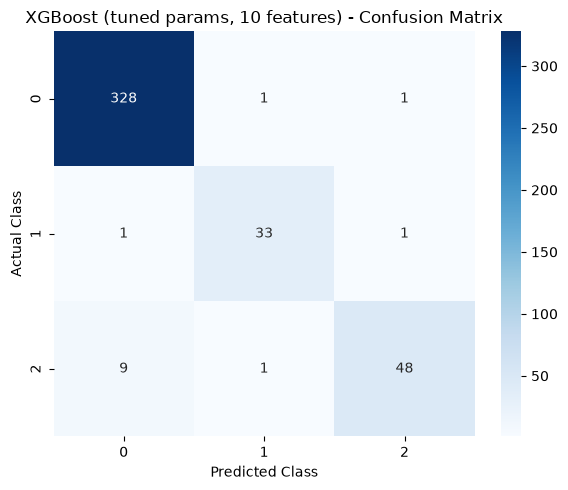

In [11]:
fig = plot_confusion_matrix(
    y_test,
    fitted_reduced[(f"{best_model_name} (tuned params)", f"Top {TOP_N} features")].predict(X_test[selected_features]),
    f"{best_model_name} (tuned params, {TOP_N} features) - Confusion Matrix",
    save_path=FIG_DIR / "reduced_feature_confusion_matrix.png",
)
plt.show()

## 6. Save models and metadata

Each model is saved next to a metadata file that records the exact feature list, library versions
and test scores, so the pickles are never used with the wrong columns.

In [12]:
reduced_model = fitted_reduced[(f"{best_model_name} (tuned params)", f"Top {TOP_N} features")]

joblib.dump(best_tuned_model, MODEL_DIR / "tuned_model.pkl")
joblib.dump(reduced_model, MODEL_DIR / "reduced_feature_model.pkl")

reduced_scores = summarize(y_test, reduced_model.predict(X_test[selected_features]))
metadata = {
    "target": TARGET,
    "random_seed": SEED,
    "model_family": best_model_name,
    "best_params": {k: (v if v is None or isinstance(v, (int, float, str)) else str(v))
                    for k, v in grid_search.best_params_.items()},
    "tuned_model": {
        "file": "tuned_model.pkl",
        "features": list(X_train.columns),
        "test_metrics": {k: round(float(v), 4) for k, v in tuned_scores.items()},
    },
    "reduced_feature_model": {
        "file": "reduced_feature_model.pkl",
        "features": selected_features,
        "test_metrics": {k: round(float(v), 4) for k, v in reduced_scores.items()},
    },
    "class_labels": "Integer ids 0/1/2 - meaning not stored in the data; see README 'Class labels'.",
    "library_versions": {
        "python": sys.version.split()[0],
        "scikit-learn": sklearn.__version__,
        "xgboost": xgboost.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
    },
}
(MODEL_DIR / "model_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("Saved: tuned_model.pkl, reduced_feature_model.pkl, model_metadata.json")

Saved: tuned_model.pkl, reduced_feature_model.pkl, model_metadata.json


## Summary

The cell below prints the headline numbers straight from the saved results, so this summary can
never drift out of sync with the tables above.

In [13]:
cv_best = cv_results.iloc[0]
print(f"Best baseline (CV Macro F1): {cv_best['Model']}  {cv_best['CV Macro F1 (mean)']:.4f} +/- {cv_best['CV Macro F1 (std)']:.4f}")
print(f"Tuned {best_model_name}: CV Macro F1 {grid_search.best_score_:.4f} | "
      f"test Macro F1 {tuned_scores['Macro F1']:.4f} (95% CI {ci_lo:.4f}-{ci_hi:.4f}), "
      f"test accuracy {tuned_scores['Accuracy']:.4f}")
print()
print("21 vs 10 features (same model settings):")
display(fs_comparison[["Model", "Feature set", "CV Macro F1 (mean)", "Test Macro F1"]].round(4))

Best baseline (CV Macro F1): XGBoost  0.8969 +/- 0.0241
Tuned XGBoost: CV Macro F1 0.9005 | test Macro F1 0.9511 (95% CI 0.9205-0.9765), test accuracy 0.9716

21 vs 10 features (same model settings):


,Model,Feature set,CV Macro F1 (mean),Test Macro F1
0,Random Forest (200 trees),All 21 features,0.8808,0.9383
1,Random Forest (200 trees),Top 10 features,0.8784,0.9227
2,XGBoost (tuned params),All 21 features,0.8981,0.9511
3,XGBoost (tuned params),Top 10 features,0.8932,0.9379
